# Actividad A

Se analiza una pista musical del dataset `GTZAN music/speech collection`. La copia de trabajo es `Datos/Senal_1D/GTZAN/trabajo/musica_bagpipe.wav`. El archivo es un audio WAV PCM mono de 16 bits, muestreado a 22050 [Hz] y con una duración declarada de 30 segundos.

La señal se representa como `x[n]`, donde `n` es el índice de muestra. Como la frecuencia de muestreo es positiva y uniforme, se calcula el eje temporal mediante `t[n] = n / fs`. La amplitud se expresa como amplitud digital normalizada.

## Primer vistazo

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

ruta = Path("../Datos/Senal_1D/GTZAN/trabajo/musica_bagpipe.wav")

fs, muestras = wavfile.read(ruta)

n = np.arange(muestras.size)
tiempo = n / fs
muestras_float = muestras.astype(np.float64)
escala = np.iinfo(muestras.dtype).max if np.issubdtype(muestras.dtype, np.integer) else np.max(np.abs(muestras_float))
amplitud = muestras_float / escala

print("Frecuencia de muestreo [Hz]:", fs)
print("Duracion [s]:", muestras.size / fs)
print("Numero de muestras:", muestras.size)
print("Rango PCM:", int(muestras.min()), "a", int(muestras.max()))
print("Rango normalizado:", float(amplitud.min()), "a", float(amplitud.max()))

Frecuencia de muestreo [Hz]: 22050
Duracion [s]: 30.0
Numero de muestras: 661500
Rango PCM: -15756 a 16956
Rango normalizado: -0.48084963530381175 a 0.5174718466750083


## Inspección de calidad y convenciones

La columna de interés es la amplitud PCM de cada muestra. Se conserva el archivo original y se usa una copia en punto flotante para la visualización. La normalización divide por el máximo representable de `int16`; no transforma la señal guardada ni la interpreta como una unidad fisica calibrada.

In [2]:
valores_no_finitos = int((~np.isfinite(muestras_float)).sum())
silencios = int(np.count_nonzero(muestras == 0))
paso_temporal = np.diff(tiempo)

print("Valores no finitos:", valores_no_finitos)
print("Muestras exactamente en cero:", silencios)
print("Paso temporal esperado (s):", 1 / fs)
print("Paso temporal observado constante:", bool(np.allclose(paso_temporal, 1 / fs)))
print("Primer tiempo (s):", float(tiempo[0]))
print("Ultimo tiempo (s):", float(tiempo[-1]))

if valores_no_finitos != 0:
    raise ValueError("La señal contiene valores no finitos")

Valores no finitos: 0
Muestras exactamente en cero: 192
Paso temporal esperado (s): 4.5351473922902495e-05
Paso temporal observado constante: True
Primer tiempo (s): 0.0
Ultimo tiempo (s): 29.999954648526078


## Visualización de la señal

La primera figura muestra los 30 segundos completos. La segunda amplía los primeros 0,1 segundos para hacer visibles las muestras individuales y comprobar la escala temporal.

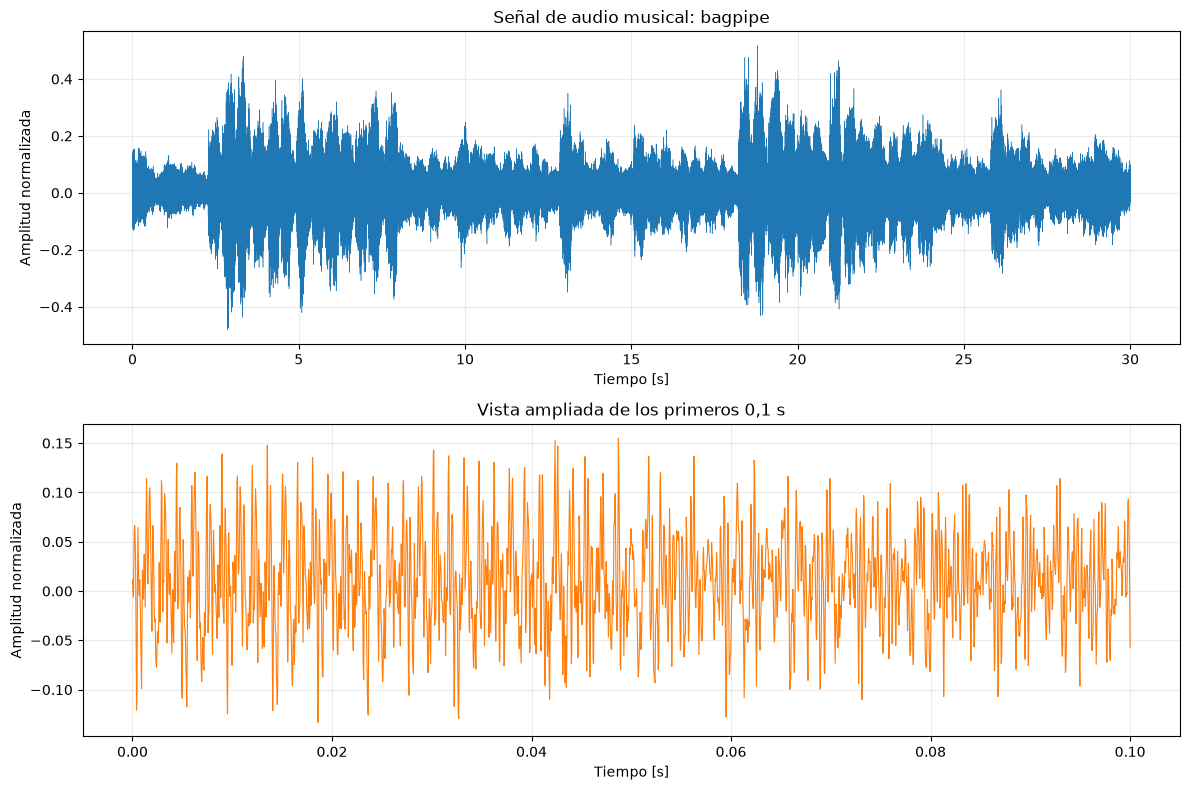

Muestras en la vista ampliada: 2206


In [3]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 8))

ejes[0].plot(tiempo, amplitud, linewidth=0.35, color="tab:blue")
ejes[0].set_title("Señal de audio musical: bagpipe")
ejes[0].set_xlabel("Tiempo [s]")
ejes[0].set_ylabel("Amplitud normalizada")
ejes[0].grid(True, alpha=0.25)

ventana = tiempo <= 0.1
ejes[1].plot(tiempo[ventana], amplitud[ventana], linewidth=0.8, color="tab:orange")
ejes[1].set_title("Vista ampliada de los primeros 0,1 s")
ejes[1].set_xlabel("Tiempo [s]")
ejes[1].set_ylabel("Amplitud normalizada")
ejes[1].grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

print("Muestras en la vista ampliada:", int(ventana.sum()))

## Interpretación y limitaciones

La señal permite observar variaciones de amplitud a lo largo del tiempo y describir su rango digital. La frecuencia de muestreo uniforme permite usar segundos como eje temporal. Sin embargo, la amplitud normalizada es relativa: no permite estimar presión sonora ni intensidad percibida. Tampoco se puede concluir por esta pista que todas las señales musicales tengan el mismo comportamiento. Para una aplicacion de IA harian falta más grabaciones, etiquetas consistentes, condiciones de registro y una validación separada.